In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Original MsEDM:
32 → 64 → 128 → 256 → 512 → 256 → 128 → 64 → 32 (decoder)

Slim MsEDM:
16 → 32 → 64 → 128 → 256 → 128 → 64 → 32 → 16 (decoder)

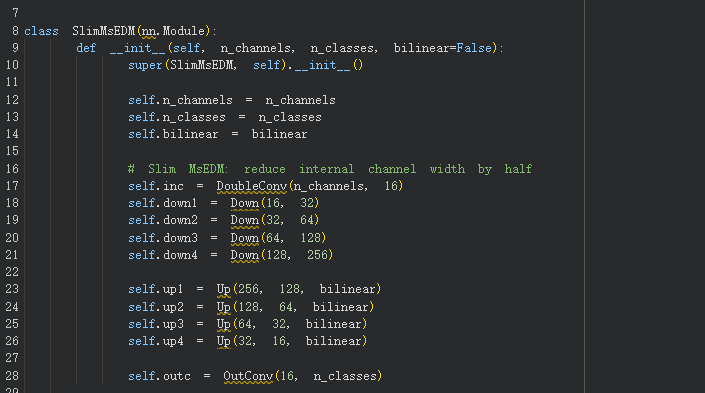

In [2]:
!pip install thop

# Params(参数量) FLOPs(浮点运算量)

In [3]:
%cd /content/drive/MyDrive/TCTL

import torch
from thop import profile, clever_format

# Original MsEDM
from model.TCTLNet_model import Unet

# Slim MsEDM
from model.TCTLNet_model_slim import SlimMsEDM


def compare_msedm(input_channels):

    original = Unet(
        n_channels=input_channels,
        n_classes=2
    )

    slim = SlimMsEDM(
        n_channels=input_channels,
        n_classes=2
    )

    x = torch.randn(1, input_channels, 256, 256)

    # FLOPs
    original_flops, _ = profile(
        original,
        inputs=(x,),
        verbose=False
    )

    slim_flops, _ = profile(
        slim,
        inputs=(x,),
        verbose=False
    )

    # Exact parameter count
    original_params = sum(p.numel() for p in original.parameters())
    slim_params = sum(p.numel() for p in slim.parameters())

    print(f"\nInput channels = {input_channels}")
    print("----------------------------------")
    print("Original MsEDM")
    print(f"Params : {original_params:,}")
    print(f"FLOPs  : {original_flops / 1e9:.3f} G")

    print("\nSlim MsEDM")
    print(f"Params : {slim_params:,}")
    print(f"FLOPs  : {slim_flops / 1e9:.3f} G")

    print("\nReduction")
    print(f"Params reduction: {(1 - slim_params/original_params)*100:.2f}%")
    print(f"FLOPs reduction : {(1 - slim_flops/original_flops)*100:.2f}%")


# L branch
compare_msedm(32)

# A/B branch
compare_msedm(64)

/content/drive/MyDrive/TCTL

Input channels = 32
----------------------------------
Original MsEDM
Params : 7,771,426
FLOPs  : 14.295 G

Slim MsEDM
Params : 1,946,770
FLOPs  : 3.742 G

Reduction
Params reduction: 74.95%
FLOPs reduction : 73.82%

Input channels = 64
----------------------------------
Original MsEDM
Params : 7,780,642
FLOPs  : 14.899 G

Slim MsEDM
Params : 1,951,378
FLOPs  : 4.044 G

Reduction
Params reduction: 74.92%
FLOPs reduction : 72.86%


In [4]:
import shutil

shutil.copy2(
    "/content/drive/MyDrive/TCTL/train.py",
    "/content/drive/MyDrive/TCTL/train_slim.py"
)

shutil.copy2(
    "/content/drive/MyDrive/TCTL/test.py",
    "/content/drive/MyDrive/TCTL/test_slim.py"
)

print("train_slim.py created")
print("test_slim.py created")

train_slim.py created
test_slim.py created


In [5]:
from pathlib import Path

# Slim training and testing scripts
files = [
    "/content/drive/MyDrive/TCTL/train_slim.py",
    "/content/drive/MyDrive/TCTL/test_slim.py"
]

# Replace Original TCTL model with Slim-MsEDM TCTL model
old_import = "from model.TCTLNet_model import TCTLNet"
new_import = "from model.TCTLNet_model_slim import TCTLNet"

for file in files:
    path = Path(file)
    text = path.read_text()

    text = text.replace(old_import, new_import)

    path.write_text(text)

    print(f"Modified: {file}")

Modified: /content/drive/MyDrive/TCTL/train_slim.py
Modified: /content/drive/MyDrive/TCTL/test_slim.py


In [11]:
# Split dataset into train, validation, and test sets
import os
import random
import shutil

raw_dir = r"C:\Users\Ur Mom\OneDrive - Griffith University\STAT3007 Deep Learning\Project-test/TCTL/data/raw"
ref_dir = r"C:\Users\Ur Mom\OneDrive - Griffith University\STAT3007 Deep Learning\Project-test/TCTL/data/ref"

save_dir = r"C:\Users\Ur Mom\OneDrive - Griffith University\STAT3007 Deep Learning\Project-test/TCTL/split_data"

files = sorted([
    f for f in os.listdir(raw_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

random.seed(42)
random.shuffle(files)

train_files = files[:720]
val_files = files[720:800]
test_files = files[800:890]

for split, split_files in [
    ("train", train_files),
    ("val", val_files),
    ("test", test_files)
]:
    os.makedirs(f"{save_dir}/{split}/raw", exist_ok=True)
    os.makedirs(f"{save_dir}/{split}/ref", exist_ok=True)

    for f in split_files:
        shutil.copy2(
            os.path.join(raw_dir, f),
            os.path.join(save_dir, split, "raw", f)
        )

        shutil.copy2(
            os.path.join(ref_dir, f),
            os.path.join(save_dir, split, "ref", f)
        )

print("Train:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))
print("Total:", len(train_files) + len(val_files) + len(test_files))

Train: 720
Validation: 80
Test: 90
Total: 890


In [4]:
!cd C:\Users\Ur Mom\OneDrive - Griffith University\STAT3007 Deep Learning\Project-test

In [7]:
import os

print("Current working directory:", os.getcwd())
print("Raw directory:", raw_dir)
print("Raw directory exists:", os.path.exists(raw_dir))

Current working directory: c:\Users\Ur Mom\OneDrive - Griffith University\STAT3007 Deep Learning\Project-test\TCTL
Raw directory: /TCTL/data/raw
Raw directory exists: False


In [ ]:
# Generate necessary txt files (color transfer parameters)

import os
import cv2
import numpy as np

ref_dir = "/content/drive/MyDrive/TCTL/split_data/train/ref"
txt_dir = "/content/drive/MyDrive/TCTL/split_data/train/txt"

output_size = (256, 256)

os.makedirs(txt_dir, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

for filename in sorted(os.listdir(ref_dir)):

    name, ext = os.path.splitext(filename)

    if ext.lower() not in image_extensions:
        continue

    path = os.path.join(ref_dir, filename)

    # Read reference image exactly like original code
    img = cv2.imread(path)

    if img is None:
        print(f"WARNING: Could not read {filename}")
        continue

    # Resize to 256x256, matching output_size in TrainDataset
    img = cv2.resize(img, output_size)

    # Convert uint8 BGR [0,255] -> float32 BGR [0,1]
    img = img.astype(np.float32) / 255.0

    # Convert to Lab exactly like original code
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

    # Calculate mean and std exactly like trans_np()
    mean = np.mean(lab, axis=(0, 1))
    std = np.std(lab, axis=(0, 1))

    # IMPORTANT:
    # Network expects:
    # [L_mean, A_mean, B_mean, L_std, A_std, B_std]
    true_num = np.concatenate([mean, std])

    txt_path = os.path.join(txt_dir, name + ".txt")

    with open(txt_path, "w") as f:
        f.write(",".join(f"{x:.10f}" for x in true_num))

    print(f"{filename}")
    print(f"  mean: {mean}")
    print(f"  std : {std}")
    print(f"  TXT : {txt_path}")

print("\nDone.")
print("TXT数量:", len(os.listdir(txt_dir)))

# Training

In [ ]:
%cd /content/drive/MyDrive/TCTL

!python train_slim.py \
    --dataroot split_data/train \
    --name tctl_slim_msedm_40 \
    --epochs 40 \
    --num_workers 2

# Testing


In [ ]:
%cd /content/drive/MyDrive/TCTL

!python test_slim.py \
    --dataroot split_data/val \
    --name tctl_slim_msedm_40 \
    --num_worker 2 \
    --suffix val

In [ ]:
import os

result_dir = "/content/drive/MyDrive/TCTL/results/tctl_slim_msedm_40_val"

print("Validation result images:", len(os.listdir(result_dir)))

In [ ]:
%cd /content/drive/MyDrive/TCTL

!python test_slim.py \
    --dataroot split_data/test \
    --name tctl_slim_msedm_40 \
    --num_worker 2 \
    --suffix test

In [ ]:
import os

test_result_dir = "/content/drive/MyDrive/TCTL/results/tctl_slim_msedm_40_test"

print("Test result images:", len(os.listdir(test_result_dir)))

# average PSNR and average SSIM

In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

result_dir = "/content/drive/MyDrive/TCTL/results/tctl_slim_msedm_40_val"
ref_dir = "/content/drive/MyDrive/TCTL/split_data/val/ref"

psnr_values = []
ssim_values = []

result_files = sorted([
    f for f in os.listdir(result_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])


for filename in result_files:

    result_path = os.path.join(result_dir, filename)
    ref_path = os.path.join(ref_dir, filename)

    if not os.path.exists(ref_path):
        print("without Reference:", filename)
        continue

    result_img = Image.open(result_path).convert("RGB")
    ref_img = Image.open(ref_path).convert("RGB")

    if ref_img.size != result_img.size:
        ref_img = ref_img.resize(result_img.size)

    result = np.asarray(result_img).astype(np.float32) / 255.0
    reference = np.asarray(ref_img).astype(np.float32) / 255.0

    psnr = peak_signal_noise_ratio(
        reference,
        result,
        data_range=1.0
    )

    ssim = structural_similarity(
        reference,
        result,
        channel_axis=-1,
        data_range=1.0
    )

    psnr_values.append(psnr)
    ssim_values.append(ssim)

print(f"Average PSNR: {np.mean(psnr_values):.4f} dB")
print(f"Average SSIM: {np.mean(ssim_values):.4f}")

In [ ]:
import os
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

result_dir = "/content/drive/MyDrive/TCTL/results/tctl_slim_msedm_40_test"
ref_dir = "/content/drive/MyDrive/TCTL/split_data/test/ref"

psnr_values = []
ssim_values = []

result_files = sorted([
    f for f in os.listdir(result_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])


for filename in result_files:

    result_path = os.path.join(result_dir, filename)
    ref_path = os.path.join(ref_dir, filename)

    if not os.path.exists(ref_path):
        print("without Reference:", filename)
        continue

    result_img = Image.open(result_path).convert("RGB")
    ref_img = Image.open(ref_path).convert("RGB")

    if ref_img.size != result_img.size:
        ref_img = ref_img.resize(result_img.size)

    result = np.asarray(result_img).astype(np.float32) / 255.0
    reference = np.asarray(ref_img).astype(np.float32) / 255.0

    psnr = peak_signal_noise_ratio(
        reference,
        result,
        data_range=1.0
    )

    ssim = structural_similarity(
        reference,
        result,
        channel_axis=-1,
        data_range=1.0
    )

    psnr_values.append(psnr)
    ssim_values.append(ssim)

print(f"Average PSNR: {np.mean(psnr_values):.4f} dB")
print(f"Average SSIM: {np.mean(ssim_values):.4f}")